# 00 — APTOS dataset audit

**Purpose.** I use this notebook to reconcile the superseded third-party copy with the official APTOS 2019 Kaggle competition download, then profile the labeled images before running notebook 01.

| | |
|---|---|
| **Inputs** | The old local copy, official `train.csv` and `train_images/`, and the local per-ID SHA-256 comparison report |
| **Outputs** | Per-image metadata and aggregate CSV/JSON tables saved under git-ignored `data/processed/aptos_dataset_audit/` |
| **Rules** | I profile labeled images only. I may read the official `test.csv` schema and IDs, but I never open, hash, decode, or profile official test-image files. I do not save image examples or per-image output in this notebook. |

I run this notebook before notebook 01. It uses `scripts/audit.py` to perform the repeatable audit, while presenting only aggregate tables and plots. I keep the official competition test set sealed until final evaluation because it is unlabeled.

## 0. Setup

The audit script reads the comparison CSV, inventories both labeled sources, extracts native image metadata, and writes local-only outputs. If all outputs already exist, setup loads the saved summary and aggregate tables instead of profiling again. Set `FORCE_REBUILD = True` to rerun. The official test-image directory is never enumerated or opened.

In [5]:
from pathlib import Path
import json
import importlib
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Project Dir
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "scripts" / "audit.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "scripts" / "audit.py").is_file():
    raise FileNotFoundError("Run this notebook from the project root or notebooks/.")

for path in (PROJECT_ROOT, PROJECT_ROOT / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

# Import from scripts/audit
import scripts.audit as audit_module
audit_module = importlib.reload(audit_module)
audit_outputs_exist = audit_module.audit_outputs_exist
run_dataset_audit = audit_module.run_dataset_audit


# Data Set dir
OLD_ROOT = PROJECT_ROOT / "data" / "raw" / "APTOS-2019"
OFFICIAL_ROOT = PROJECT_ROOT / "data" / "raw" / "APTOS-2019-kaggle-competition"

# Output dir
COMPARISON_REPORT = PROJECT_ROOT / "data" / "processed" / "aptos_source_comparison.csv"
AUDIT_OUTPUT = PROJECT_ROOT / "data" / "processed" / "aptos_dataset_audit"

sns.set_theme(style="whitegrid", context="notebook")
FORCE_REBUILD = False


AUDIT_FILES = {
    "old_metadata": AUDIT_OUTPUT / "old_image_metadata.csv",
    "official_metadata": AUDIT_OUTPUT / "official_train_image_metadata.csv",
    "class_distribution": AUDIT_OUTPUT / "class_distribution.csv",
    "resolution_distribution": AUDIT_OUTPUT / "resolution_distribution_by_grade.csv",
    "summary": AUDIT_OUTPUT / "audit_summary.json",
}

if FORCE_REBUILD or not audit_outputs_exist(AUDIT_OUTPUT):
    audit_result = run_dataset_audit(
        OLD_ROOT,
        OFFICIAL_ROOT,
        COMPARISON_REPORT,
        AUDIT_OUTPUT,
        n_jobs=1,
        include_fov=False,
        show_progress=True,
    )
    audit_summary = audit_result["summary"]
    class_distribution = audit_result["class_distribution"]
    resolution_distribution = audit_result["resolution_distribution"]
    
    print(f"Audit complete. Outputs saved under {AUDIT_OUTPUT.relative_to(PROJECT_ROOT)}.")
else:
    audit_summary = json.loads(AUDIT_FILES["summary"].read_text(encoding="utf-8"))
    class_distribution = pd.read_csv(AUDIT_FILES["class_distribution"])
    resolution_distribution = pd.read_csv(AUDIT_FILES["resolution_distribution"])
    
    audit_result = {
        "summary": audit_summary,
        "class_distribution": class_distribution,
        "resolution_distribution": resolution_distribution,
    }
    print(f"Existing audit metadata is present under {AUDIT_OUTPUT.relative_to(PROJECT_ROOT)}; profiling skipped.")

Profiling images:   0%|          | 0/3662 [00:00<?, ?it/s]

Profiling images:   0%|          | 0/3662 [00:00<?, ?it/s]

Audit complete. Outputs saved under data/processed/aptos_dataset_audit.


In [41]:
display(pd.DataFrame(audit_summary).head())

,audit_complete,csv_schemas,image_inventory,source_comparison_report,metadata_comparison,class_balance,resolution_summary,official_test_handling,output_files
old_copy,True,"{'train': {'columns': ['id_code', 'diagnosis']...",NaN,NaN,NaN,"{'counts_by_grade': {'0': 1805, '1': 370, '2':...",{'distinct_resolution_pairs': 17},NaN,NaN
official_train,True,"{'train.csv': {'columns': ['id_code', 'diagnos...","{'csv_rows': 3662, 'image_files': 3662, 'csv_i...",NaN,NaN,"{'counts_by_grade': {'0': 1805, '1': 370, '2':...",{'distinct_resolution_pairs': 17},NaN,NaN
official_test,True,"{'test.csv': {'columns': ['id_code'], 'rows': ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN
old_copy_by_split,True,NaN,"{'train': {'csv_rows': 2930, 'image_files': 29...",NaN,NaN,NaN,NaN,NaN,NaN
old_copy_profiled_images,True,NaN,3662,NaN,NaN,NaN,NaN,NaN,NaN


In [42]:
display(class_distribution)

,source,split,diagnosis,count,fraction
0,official_train,all,0,1805,0.492900
1,official_train,all,1,370,0.101038
2,official_train,all,2,999,0.272802
3,official_train,all,3,193,0.052703
4,official_train,all,4,295,0.080557
5,official_train,train,0,1805,0.492900
6,official_train,train,1,370,0.101038
7,official_train,train,2,999,0.272802
8,official_train,train,3,193,0.052703
9,official_train,train,4,295,0.080557


In [43]:
display(resolution_distribution)

,source,split,diagnosis,width,height,count,resolution
0,official_train,all,0,819,614,279,819x614
1,official_train,all,0,1050,1050,901,1050x1050
2,official_train,all,0,1476,1117,10,1476x1117
3,official_train,all,0,2048,1536,351,2048x1536
4,official_train,all,0,2416,1736,31,2416x1736
...,...,...,...,...,...,...,...
298,old_copy,val,4,2416,1736,3,2416x1736
299,old_copy,val,4,2588,1958,8,2588x1958
300,old_copy,val,4,3216,2136,5,3216x2136
301,old_copy,val,4,3388,2588,2,3388x2588


## 0.1 Source files, schemas, and reconciliation

Check the CSV columns and row totals, the image-to-row inventories, and the previously generated ID/label/hash comparison. The old copy's partition named `test` is only an uploader-defined split; the source comparison determines whether those images belong to the official competition training set.

In [15]:
schema_rows = []
for source, files in audit_summary["csv_schemas"].items():
    if "columns" in files and "rows" in files:
        file_schemas = [(f"{source}.csv", files)]
    else:
        file_schemas = files.items()
    for filename, details in file_schemas:
        schema_rows.append(
            {
                "source": source,
                "file": filename,
                "rows": details["rows"],
                "columns": ", ".join(details["columns"]),
            }
        )


In [ ]:
# Complete data split and columns
display(pd.DataFrame(schema_rows))

,source,file,rows,columns
0,old_copy,train,2930,"id_code, diagnosis"
1,old_copy,val,366,"id_code, diagnosis"
2,old_copy,test,366,"id_code, diagnosis"
3,official_train,train.csv,3662,"id_code, diagnosis"
4,official_test,test.csv,1928,id_code


In [ ]:
# Distribution of old data split 
display(pd.DataFrame(audit_summary["image_inventory"]["old_copy_by_split"]).T)

,csv_rows,image_files,csv_ids_missing_images,images_without_csv_rows
train,2930,2930,0,0
val,366,366,0,0
test,366,366,0,0


In [ ]:
# Distribution of data in official dataset
display(pd.DataFrame([audit_summary["image_inventory"]["official_train"]], index=["official_train"]))

,csv_rows,image_files,csv_ids_missing_images,images_without_csv_rows
official_train,3662,3662,0,0


In [ ]:
# Complete source comparison 
display(pd.DataFrame([audit_summary["source_comparison_report"]], index=["comparison"]))

,old_report_ids,official_train_report_ids,common_ids,old_only_ids,official_train_only_ids,matching_labels,mismatching_labels,identical_byte_hashes,different_byte_hashes,old_report_label_mismatches_against_old_csv,official_report_label_mismatches_against_train_csv
comparison,3662,3662,3662,0,0,3662,0,3662,0,0,0


## 0.2 Grade counts and class imbalance

Compare grade counts for the complete old copy and official training set. The `all` rows combine the old uploader's train/validation/test partitions; the partition rows are retained to show how that copy was arranged.

,source,split,diagnosis,count,fraction
0,official_train,all,0,1805,0.492900
1,official_train,all,1,370,0.101038
2,official_train,all,2,999,0.272802
3,official_train,all,3,193,0.052703
4,official_train,all,4,295,0.080557
10,old_copy,all,0,1805,0.492900
11,old_copy,all,1,370,0.101038
12,old_copy,all,2,999,0.272802
13,old_copy,all,3,193,0.052703
14,old_copy,all,4,295,0.080557


In [26]:
all_class_counts = class_distribution.query("split == 'all'").copy()
display(
    all_class_counts.pivot(index="diagnosis", columns="source", values="count")
    .rename_axis("grade")
)
display(pd.DataFrame(audit_summary["class_balance"]).T)

source,official_train,old_copy
grade,,
0,1805,1805
1,370,370
2,999,999
3,193,193
4,295,295


,counts_by_grade,missing_grades,largest_to_smallest_present_class_ratio
official_train,"{'0': 1805, '1': 370, '2': 999, '3': 193, '4':...",[],9.352332
old_copy,"{'0': 1805, '1': 370, '2': 999, '3': 193, '4':...",[],9.352332


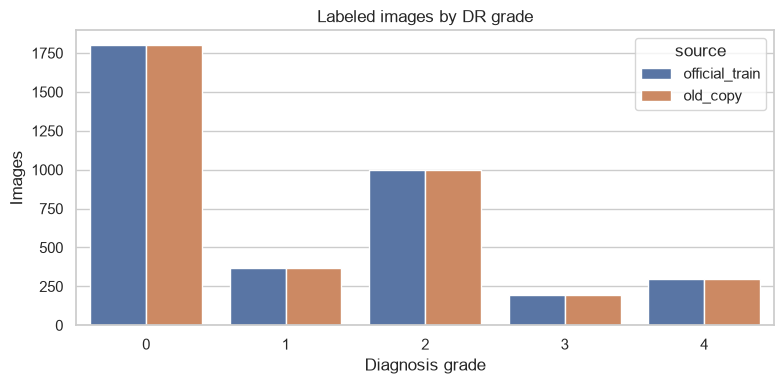

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=all_class_counts,
    x="diagnosis",
    y="count",
    hue="source",
    order=range(5),
    ax=ax,
)
ax.set(title="Labeled images by DR grade", xlabel="Diagnosis grade", ylabel="Images")
plt.tight_layout()
plt.show()

## 0.3 Native resolution inventory

A resolution is the exact `(width, height)` pair from the decoded image. Counts are shown for each source and are not a preprocessing result.

In [ ]:
all_resolution_counts = resolution_distribution.query("split == 'all'")
resolution_totals = (
    all_resolution_counts.groupby(["source", "resolution"], as_index=False)["count"]
    .sum().sort_values(["source", "count"], ascending=[True, False])
)

display(
    resolution_totals.groupby("source").agg(
        distinct_resolutions=("resolution", "nunique"),
        images=("count", "sum"),
    )
)


,distinct_resolutions,images
source,,
official_train,17,3662
old_copy,17,3662


In [32]:
display(resolution_totals.groupby("source", group_keys=False).head(12))

,source,resolution,count
0,official_train,1050x1050,974
8,official_train,2416x1736,638
9,official_train,2588x1958,533
11,official_train,3216x2136,410
5,official_train,2048x1536,351
16,official_train,819x614,287
12,official_train,3388x2588,141
3,official_train,1504x1000,92
4,official_train,1844x1226,61
13,official_train,4288x2848,52


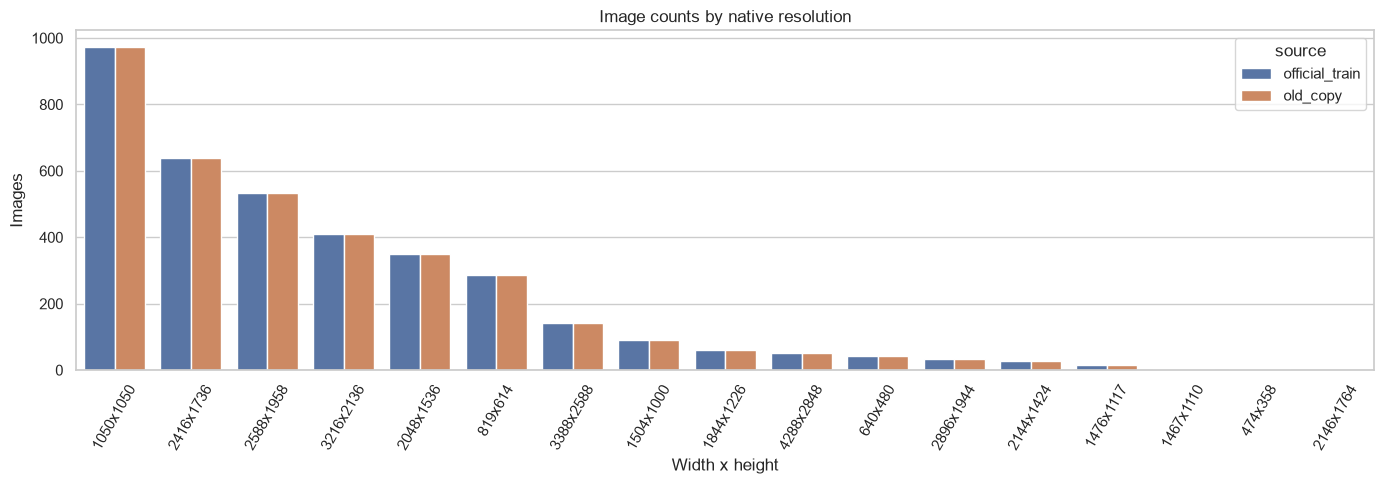

In [34]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(
    data=resolution_totals,
    x="resolution",
    y="count",
    hue="source",
    ax=ax,
)
ax.set(title="Image counts by native resolution", xlabel="Width x height", ylabel="Images")
ax.tick_params(axis="x", labelrotation=60)
plt.tight_layout()
plt.show()

## 0.4 Resolution by grade

This heatmap uses counts, not percentages. A concentration of grades in particular resolutions is a potential acquisition shortcut to investigate in notebook 01; it does not show that resolution causes a grade or that any individual image was misgraded.

In [37]:
official_resolution_by_grade = resolution_distribution.query(
    "source == 'official_train' and split == 'all'"
)
grade_resolution = official_resolution_by_grade.pivot(
    index="resolution",
    columns="diagnosis",
    values="count",
).fillna(0)
grade_resolution = grade_resolution.loc[
    grade_resolution.sum(axis=1).sort_values(ascending=False).index
]
display(grade_resolution.astype(int))



diagnosis,0,1,2,3,4
resolution,,,,,
1050x1050,901,19,39,2,13
2416x1736,31,234,233,60,80
2588x1958,231,44,165,47,46
3216x2136,2,13,307,32,56
2048x1536,351,0,0,0,0
819x614,279,7,1,0,0
3388x2588,0,13,91,6,31
1504x1000,0,2,63,9,18
1844x1226,0,13,28,1,19


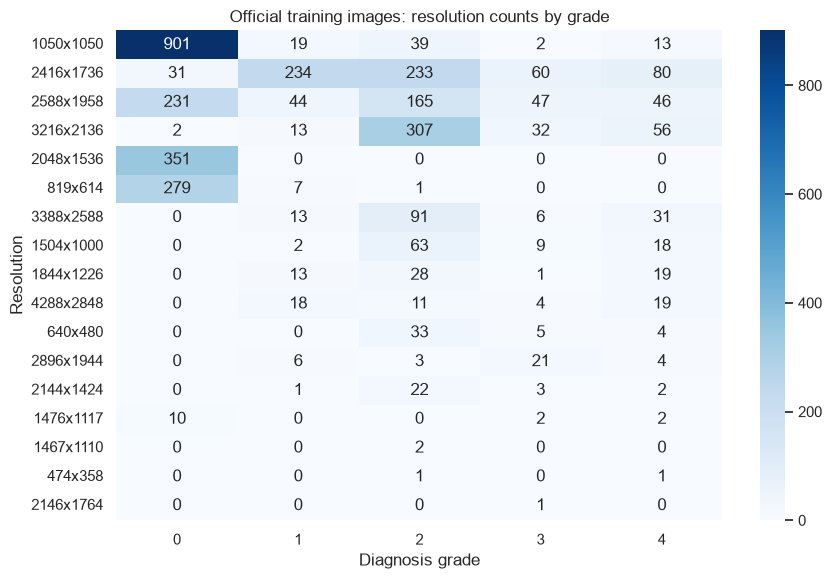

In [38]:
fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(grade_resolution))))
sns.heatmap(grade_resolution, annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set(title="Official training images: resolution counts by grade", xlabel="Diagnosis grade", ylabel="Resolution")
plt.tight_layout()
plt.show()

## 0.5 Observations and decisions

### What I verified

- I compared the old copy’s three labeled folders with the official `train_images`. Their image IDs, labels, and exact file-byte SHA-256 hashes match. This means the old copy’s folder named `test` is **not** the Kaggle competition test set; it contains images that are part of the official training set.

- I confirmed that the official `test.csv` has an `id_code` column but *no diagnosis* column. The audit reports its row count and does not open or hash any official test-image files.

- The generated class-distribution table shows that the grades are imbalanced, with grade 3 as the smallest class. I’ll keep exact counts and ratios in the git-ignored audit output and won’t include them in public materials unless sharing is cleared.

### Decisions I’m making

- I’ll use only the official competition download as the active data source. The old copy is not additional data, and its earlier folder names do not change the official train/test boundary. I’ll keep the two dataset roots separate and use official training files for new experiments.

- For the baseline, I’ll create a reproducible stratified train/validation split from the official labeled training data. I’ll create a local held-out test split only if needed, and group confirmed duplicates before splitting. I won’t use the unlabeled Kaggle test set for validation or claim patient-level separation, since patient IDs are unavailable.

- I won’t undersample or oversample solely because the classes are imbalanced. I’ll preserve the observed distribution, stratify the partitions, and report QWK and per-grade metrics. I’ll consider class weighting only as a later experiment evaluated on the validation set.

- I’ll treat resolution-grade associations in the plot as a shortcut-audit signal, not a clinical conclusion. After running this notebook, I’ll record the exact resolution counts and investigate them in notebook 01.

### Privacy and provenance

Matching file bytes confirms that the old and official copies contain identical image files; it does not establish the old uploader’s provenance or license. I’ll keep per-image metadata and CSV outputs local under `data/processed/`.